# 10 — Um agente central consultando três contas de negócio

**Implementação do cenário:** [Build a multi-account AI agent with AgentCore Gateway and MCP](https://aws.amazon.com/blogs/machine-learning/build-a-multi-account-ai-agent-with-agentcore-gateway-and-mcp/).

Você fará uma pergunta a um **agente Strands hospedado na AWS**. Ele descobrirá
capacidades no **Registry**, consultará **três MCP servers** por um único
**Gateway** e responderá usando **Bedrock**. A **Policy Cedar** autoriza o
usuário; o **Identity** obtém tokens M2M para as chamadas às LOBs.

**Resultado esperado:** uma visão do cliente fictício C003, combinando Retail,
Transaction e Lending, com a lista de ferramentas usadas e uma tentativa de
exclusão recusada pelo Gateway.

**Tempo:** 60–90 minutos de laboratório após preparar contas, identidade e KB.
A implantação inicial tem duração adicional, dependente dos serviços.
**Kernel:** `.venv/bin/python`, após `uv sync --frozen --extra banking`.

Consulte o [runbook](../docs/banking/README.md) para os pré-requisitos e as
adaptações. Referência fixada no commit
`f76491b63d005d1ad0c253396f58f67da021f94d`.

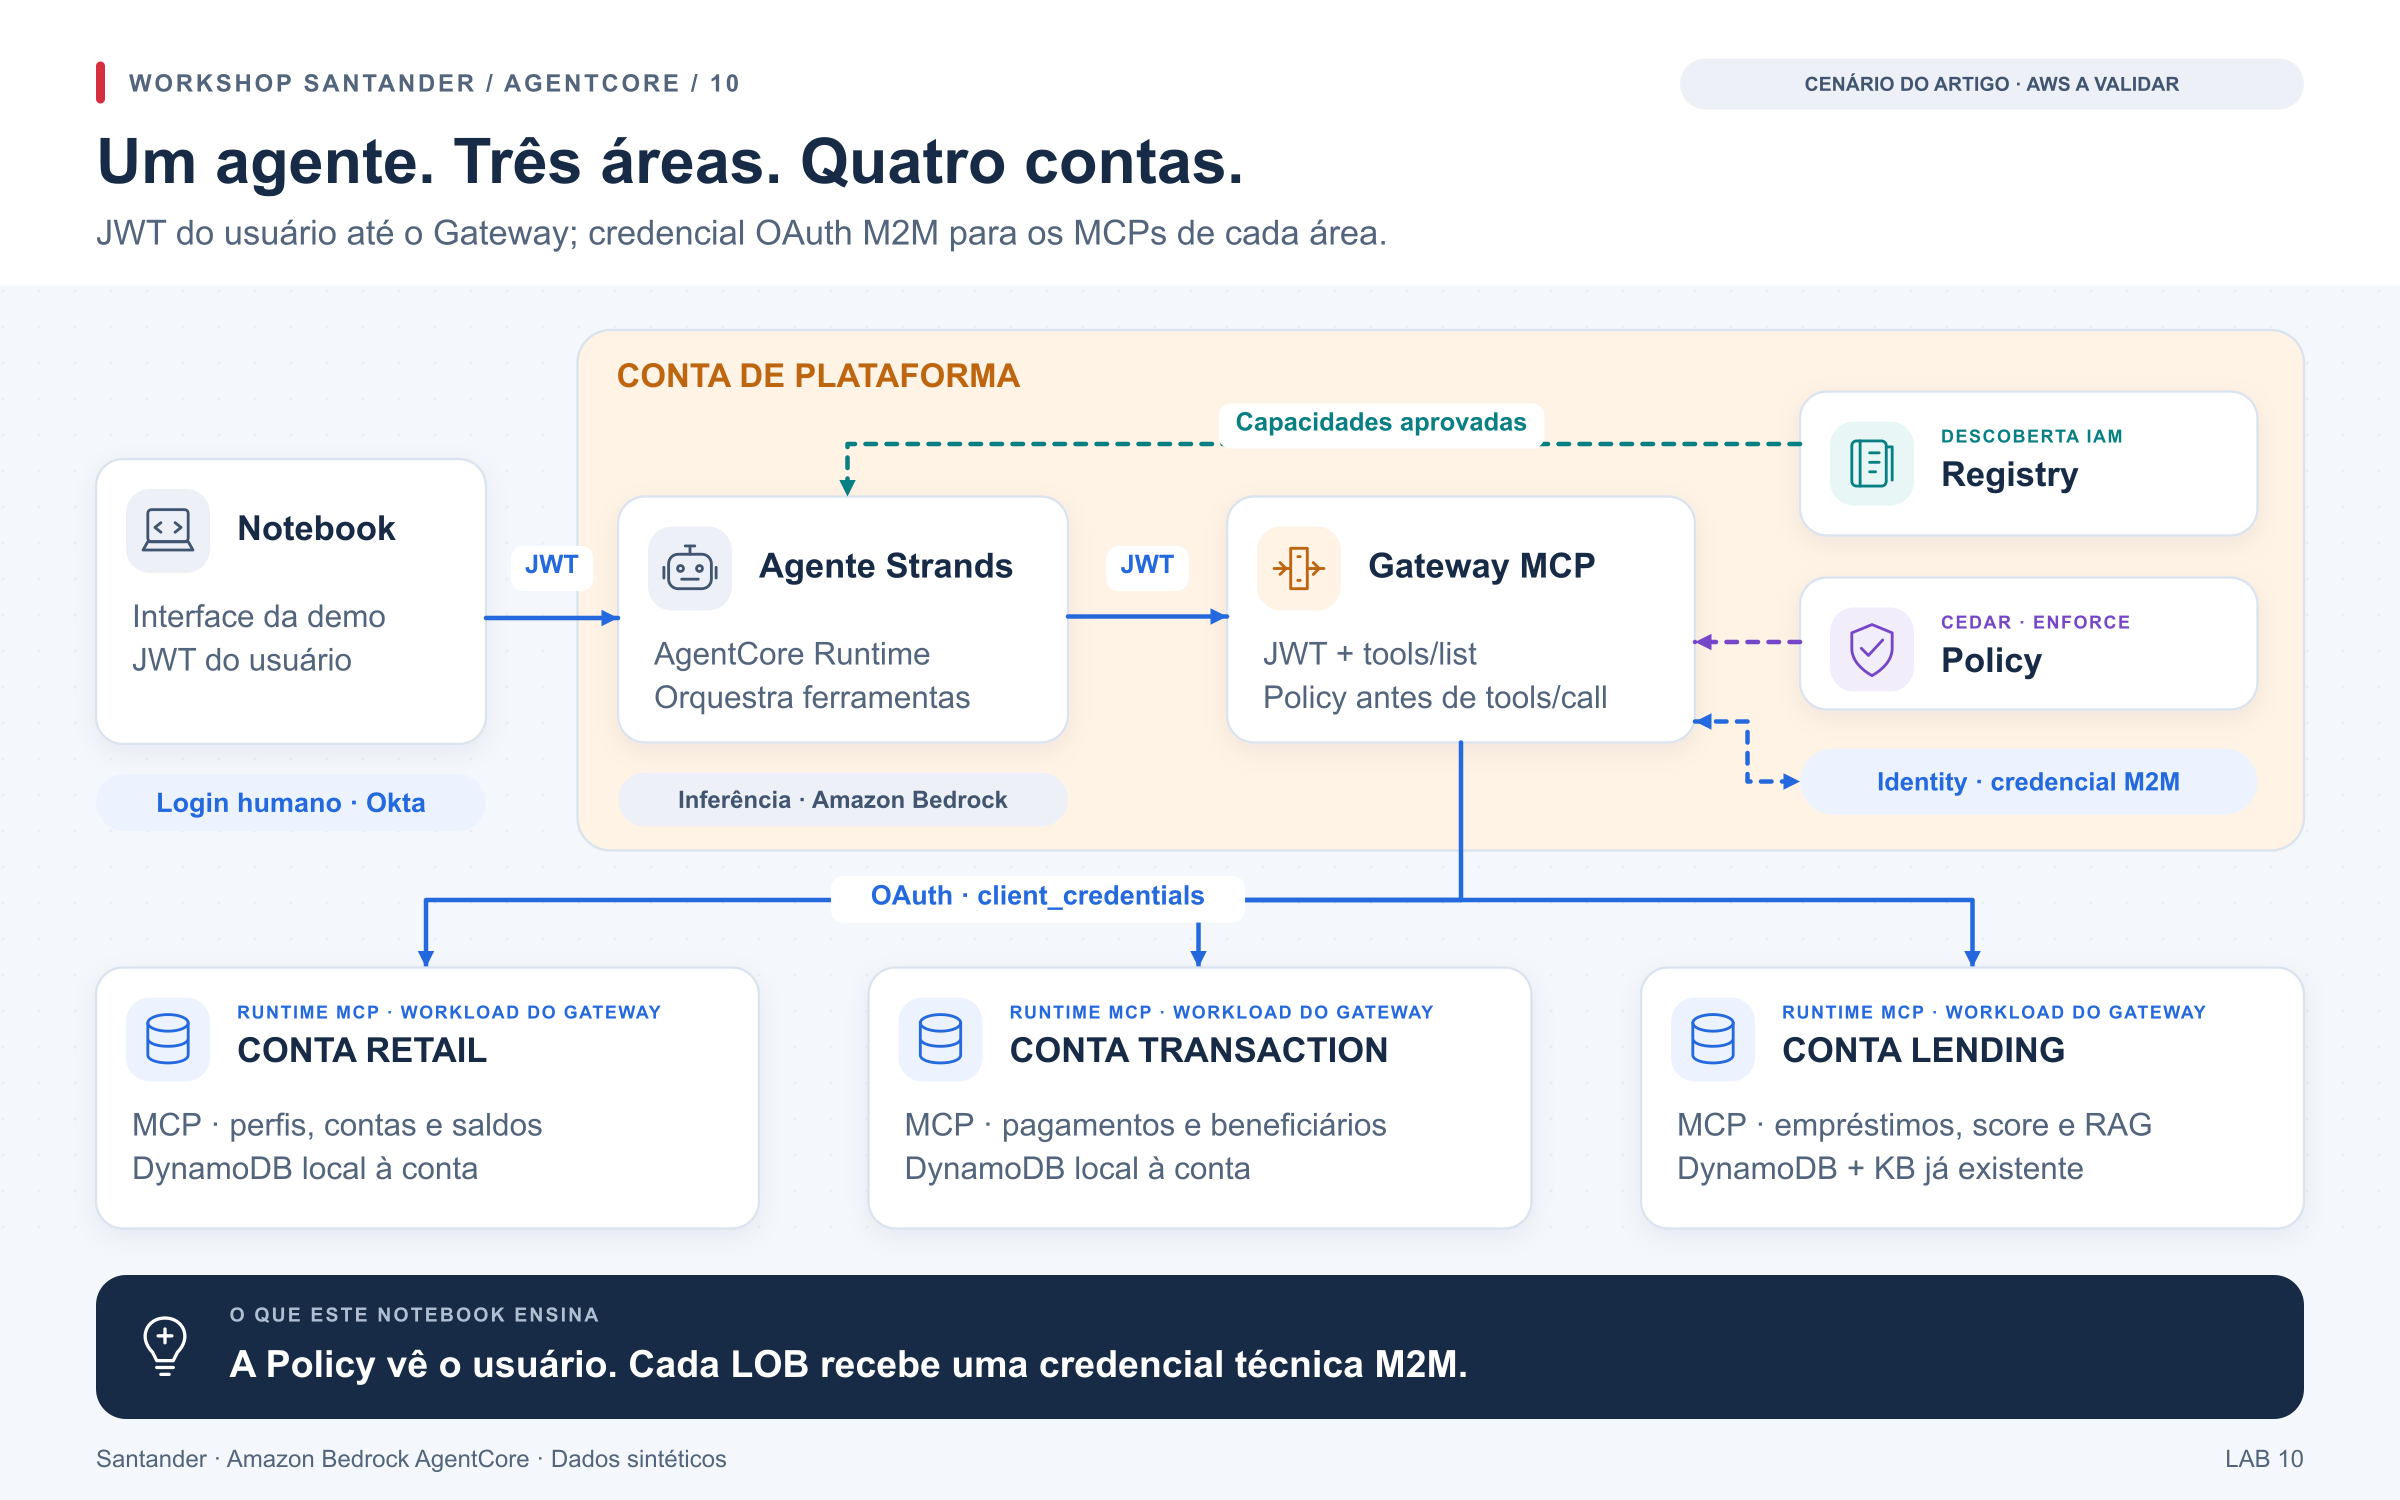

[Abrir PNG](../docs/banking/arquitetura.png) · [SVG editável](../docs/banking/arquitetura.svg)

## 1. Entenda a diferença para os notebooks 02 e 08

| Trecho | Credencial | Identidade vista no destino |
|---|---|---|
| Notebook → Agent Runtime | JWT humano Okta | Usuário autenticado |
| Agent Runtime → Gateway | O mesmo JWT humano | Usuário avaliado por Cedar |
| Gateway → MCPs das LOBs | OAuth `client_credentials` via Identity | Aplicação M2M |
| MCP → DynamoDB / KB | Execution role da própria LOB | Role IAM local |

**Este é um fluxo M2M, não OBO.** A identidade humana para no Gateway.
Os dados permanecem nas fontes, mas os resultados das consultas seguem para
o agente e para o contexto do modelo na plataforma.

O notebook ocupa o lugar de React/ECS/CloudFront. As aplicações Okta e uma
KB com documentos sintéticos ingeridos na conta Lending são pré-requisitos.
Os templates daqui criam os demais recursos do fluxo.

**Na próxima célula**, vamos importar os helpers, localizar o projeto e
definir os controles de execução. `RUN_AWS=False` mantém a preparação
offline; `DEPLOY_PHASE` seleciona uma fase de implantação e `LIVE` só
fica ativo com AWS habilitada e nenhuma fase selecionada. Os controles
`RUN_PIPELINE` e `APPLY_CHANGESET` serão usados na seção 4.
A saída mostrará o modo escolhido. Após alterar esses valores, reexecute
a célula para atualizar as variáveis usadas nas etapas seguintes.

In [ ]:
import json
import os
import subprocess
import sys
from pathlib import Path
from IPython.display import Markdown, display
from santander_demo.banking.spec import LOBS, WRITE_TOOLS, DELETE_TOOL, data_file, qualified_tools, cedar
from santander_demo.banking.client import (
    load_config, aws_sessions, prepare_phase, preflight, verify_user_token,
    call_tool, probe_delete, invoke_agent, sanitized_evidence,
)

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/santander_demo/banking").is_dir(), "Abra o notebook na pasta do projeto"

# O padrão não acessa contas e não simula respostas dos serviços.
RUN_AWS = False
DEPLOY_PHASE = None  # bootstrap → platform → lobs → bindings → agent → None
RUN_PIPELINE = False
APPLY_CHANGESET = False
CONFIG_PATH = ROOT / "config/local.banking.json"
LIVE = RUN_AWS and DEPLOY_PHASE is None
print("AWS REAL" if RUN_AWS else "PREPARAÇÃO LOCAL — integrações AWS: NOT_RUN")

## 2. Confira os três MCP servers e as 16 ferramentas

O código executado pelos Runtimes está em
[`src/santander_demo/banking/lobs`](../src/santander_demo/banking/lobs).
É uma adaptação dos servidores do artigo, com tabelas prefixadas para este lab.
Esta célula lê **contratos locais**, sem consultar dados na AWS.

Vamos carregar `tools.json`, montar uma tabela com as ferramentas de
cada LOB (área de negócio) e conferir se há dezesseis nomes qualificados.
Esperamos a tabela de Retail, Transaction e Lending seguida da confirmação
de contagem. Nenhuma ferramenta será chamada nesta etapa.

In [ ]:
schemas = data_file("tools.json")
rows = ["| Conta LOB | Ferramentas MCP |", "|---|---|"]
for lob, tools in schemas.items():
    rows.append(f"| {lob} | " + ", ".join(f"`{t['name']}`" for t in tools) + " |")
display(Markdown("\n".join(rows)))
assert len(qualified_tools()) == 16
print("16 schemas locais; nenhum backend invocado.")

Os exemplos usam clientes fictícios C001–C008. Para repetir a pergunta do
artigo, usaremos **C003 (Maria Garcia)**.

O roteiro é de consultas: as três ferramentas de escrita ficam sem `permit`
e sem IAM de escrita. `delete_customer` permanece um stub não destrutivo,
com um `forbid` explícito no Gateway. Isso permite testar a negativa sem
excluir dados, mesmo se a configuração estiver incorreta.

## 3. Gere e revise o IaC

Esta célula gera arquivos CloudFormation **localmente**. Não cria recursos.
Os templates são separados para quebrar dependências entre contas: o Gateway
existe antes dos MCPs, e os targets são associados depois dos Runtimes.

Vamos executar `infra/banking/generate.py` com o Python deste kernel,
ler os JSONs produzidos e imprimir o número de recursos declarado em
cada arquivo. A asserção final exige sete templates. Falhas do gerador
interrompem a célula; a contagem não substitui o lint da próxima etapa.

In [ ]:
subprocess.run(
    [sys.executable, str(ROOT / "infra/banking/generate.py")], cwd=ROOT, check=True
)
templates = sorted((ROOT / "infra/banking/templates").glob("*.json"))
for path in templates:
    template = json.loads(path.read_text())
    print(f"{path.name}: {len(template['Resources'])} recursos CloudFormation")
assert len(templates) == 7

Antes da implantação, no terminal:

```bash
uv run --extra banking cfn-lint infra/banking/templates/*.json
uv run --extra banking python scripts/build_artifacts.py --banking
```

Copie [banking.example.json](../config/banking.example.json) para
`config/local.banking.json`. Preencha perfis, IDs das quatro contas, issuer e
aplicações Okta, **ARN** do segredo M2M, KB Lending e ARNs de modelo.
Não coloque senha, client secret ou JWT no notebook/JSON.

Os perfis precisam corresponder às contas declaradas. A KB deve estar ativa
**e ingerida** na conta Lending. Seu bucket, PDFs e índice vetorial continuam
sob o IaC do proprietário da fonte.

**Na próxima célula**, com `RUN_AWS=True`, vamos carregar o JSON de
configuração e abrir as sessões dos quatro perfis. O helper consultará
STS para verificar se cada perfil aponta para a conta esperada e se as
quatro contas são distintas. Esperamos a mensagem `PASS`; no modo
offline, a validação será marcada como `NOT_RUN`.

In [ ]:
config = sessions = None
if RUN_AWS:
    config = load_config(CONFIG_PATH)
    sessions = aws_sessions(config)  # STS get-caller-identity nas quatro contas
    print("PASS: quatro perfis apontam para quatro contas distintas.")
else:
    print("NOT_RUN: validação dos perfis e dos identificadores AWS.")

## 4. Prepare e aplique uma fase por vez

| `DEPLOY_PHASE` | Onde | O que cria |
|---|---|---|
| `"bootstrap"` | Quatro contas | Buckets de artefato |
| `"platform"` | Plataforma | Gateway + Identity M2M + Policy engine + Guardrail + logs |
| `"lobs"` | Retail, Transaction e Lending | DynamoDB, fixtures e três Runtimes MCP |
| `"bindings"` | Plataforma | Targets, Policy e Registry |
| `"agent"` | Plataforma | Runtime Strands + Bedrock |
| `None` | Ambiente pronto | Libera preflight e invocações abaixo |

Configure `RUN_AWS=True` e uma fase. A célula prepara os parâmetros usando
outputs reais dos stacks anteriores.

Primeiro mantenha `RUN_PIPELINE=False` para revisar os comandos.
Com `RUN_PIPELINE=True`, o pipeline prepara change sets; isso inclui upload
do artefato quando necessário. Após revisá-los, use `APPLY_CHANGESET=True`
para aplicar a fase pelo CloudFormation.

Se uma implantação falhar, corrija template ou parâmetros e repita a fase.
Não execute os scripts avulsos de criação/limpeza do repositório original.

A célula abaixo montará `plans` e exibirá a conta e o comando de cada
plano da fase selecionada. Se `RUN_PIPELINE` estiver ativo, ela chamará
o wrapper do projeto; `APPLY_CHANGESET` acrescentará `--execute` ao comando.
Sem AWS habilitada ou sem fase, a saída informará que nenhuma implantação
foi selecionada.

In [ ]:
plans = []
if RUN_AWS and DEPLOY_PHASE is not None:
    plans = prepare_phase(ROOT, config, sessions, DEPLOY_PHASE)
    for plan in plans:
        print(f"Conta: {plan['account']}\n{plan['command']}\n")
    if RUN_PIPELINE:
        for plan in plans:
            command = plan["args"] + (["--execute"] if APPLY_CHANGESET else [])
            subprocess.run(command, cwd=ROOT, check=True)
else:
    print("Nenhuma fase de implantação selecionada.")

## 5. Verifique as fronteiras antes da primeira pergunta

Volte a `DEPLOY_PHASE=None` e execute novamente a configuração da seção 1.
O preflight exige três targets prontos, credenciais M2M, Gateway em
`ENFORCE`, Registry governado e os Runtimes nas contas corretas.

`READY` comprova configuração disponível; a execução será verificada pelas
chamadas seguintes. Falhas de integração interrompem o roteiro.

Vamos guardar o retorno em `environment`, que fornecerá os endpoints
e identificadores às próximas células. O resumo esperado lista as três
LOBs, `CLIENT_CREDENTIALS` e `ENFORCE`, mantendo
`invocation_verified: False`. Com `LIVE=False`, `environment` continuará
vazio e o preflight será marcado como `NOT_RUN`.

In [ ]:
environment = None
if LIVE:
    environment = preflight(config, sessions)
    print(json.dumps({
        "mode": environment["mode"],
        "accounts": 4,
        "lobs": sorted(environment["lob_runtime_arns"]),
        "policy": "ENFORCE",
        "outbound_auth": "CLIENT_CREDENTIALS",
        "invocation_verified": False,
    }, indent=2))
else:
    print("NOT_RUN: preflight real do ambiente.")

## 6. Autentique o usuário de teste

Obtenha um **access token humano** pelo fluxo Authorization Code do aplicativo
Okta de teste. O token deve ter a audiência configurada e o `sub` esperado.
O helper verifica assinatura JWKS, issuer, audiência, expiração, `sub` e `cid`.

Okta emite a identificação da aplicação em **`cid`**. Os templates verificam
essa claim via `CustomClaims`, tanto para a aplicação humana quanto para M2M.
O token nunca é impresso; permanece na memória do kernel.

Vamos receber o token por `getpass`, armazená-lo em `user_token` e
imprimir somente o resultado da verificação. Um token inválido interrompe
a etapa antes das chamadas MCP. Com `LIVE=False`, a célula não solicitará
entrada e mostrará `NOT_RUN`.

In [ ]:
user_token = None
if LIVE:
    from getpass import getpass
    user_token = getpass("Access token humano Okta (não M2M): ").strip()
    print(verify_user_token(user_token, config))
else:
    print("NOT_RUN: login e validação do JWT.")

## 7. Descubra capacidades aprovadas e liste as ferramentas do Gateway

São operações diferentes: Registry oferece metadados governados; `tools/list`
oferece o contrato MCP. Encontrar uma capacidade não autoriza `tools/call`.
A descoberta valida o endpoint antes de qualquer envio de bearer.

Vamos exibir as capacidades descobertas, abrir uma sessão autenticada
no Gateway e listar os nomes MCP anunciados. A asserção exigirá que
todas as ferramentas de consulta estejam presentes; as ferramentas de
escrita e exclusão ficam fora dessa exigência. Esperamos a lista de
capacidades e ferramentas, ou `NOT_RUN` se `LIVE` estiver desativado.

In [ ]:
if LIVE:
    from santander_demo.banking.agent import discover
    from santander_demo.cloud import gateway_session, list_tools
    capabilities = discover(sessions["platform"], environment["registry_arn"], environment["gateway_url"])
    display(Markdown("**Registry:** " + ", ".join(sorted(capabilities))))
    async with gateway_session(environment["gateway_url"], user_token, {environment["gateway_url"]}) as mcp:
        tools = await list_tools(mcp)
    names = sorted(tool.name for tool in tools)
    readable = set(qualified_tools()) - WRITE_TOOLS - {DELETE_TOOL}
    assert readable <= set(names), "Faltam ferramentas de consulta no Gateway"
    display(Markdown("\n".join("- `" + name + "`" for name in names)))
else:
    print("NOT_RUN: descoberta Registry e tools/list no Gateway.")

## 8. Cruze as três contas com chamadas MCP determinísticas

Antes de adicionar o LLM, prove que os três caminhos funcionam. Cada chamada
passa pelo Gateway da plataforma; nenhum cliente do notebook consulta
diretamente tabelas DynamoDB nas LOBs.

Vamos consultar o perfil, os pagamentos e o score do cliente fictício
`C003`, guardando as respostas em `observations`. A célula exibirá os
retornos e exigirá três entradas, uma para cada ferramenta chamada.
Com `LIVE=False`, o dicionário ficará vazio e a saída indicará `NOT_RUN`.

In [ ]:
customer_id = "C003"  # fixture sintética da referência
observations = {}
if LIVE:
    for tool in [
        "retail-banking___get_profile",
        "transaction-banking___get_payments",
        "lending-wealth___get_credit_score",
    ]:
        observations[tool] = await call_tool(environment, user_token, tool, {"customer_id": customer_id})
    display(observations)
    assert len(observations) == 3
    print("PASS: resultados reais obtidos das três LOBs.")
else:
    print("NOT_RUN: nenhuma consulta bancária executada.")

## 9. Consulte documentos na conta Lending

O MCP Lending chama `bedrock-agent-runtime.retrieve` com o execution role
daquela conta. Verifique que há trechos e referências de documentos reais
**do sandbox**. Uma KB vazia não deve ser reportada como RAG validado.

Vamos chamar `lending-wealth___search_lending_policies` com uma pergunta
sobre elegibilidade e score para um empréstimo de USD 50.000.
A asserção exigirá `results` não vazio antes de exibir o retorno.
Se `LIVE` estiver desativado, a busca documental ficará como `NOT_RUN`.

In [ ]:
if LIVE:
    policies = await call_tool(
        environment, user_token, "lending-wealth___search_lending_policies",
        {"query": "Eligibility and credit score requirements for a 50000 dollar personal loan"},
    )
    assert policies.get("results"), "A KB não devolveu trechos; verifique a ingestão pelo IaC da fonte"
    display(policies)
    print("PASS: RAG executado na conta Lending.")
else:
    print("NOT_RUN: Retrieve na Knowledge Base.")

## 10. Veja Cedar bloquear uma operação

A política permite consultas autenticadas e proíbe `delete_customer`.
O código abaixo é a mesma fonte utilizada para gerar os recursos de Policy.
Os nomes das ações incluem o prefixo real do target.

Primeiro, vamos renderizar e exibir as regras `ReadTools` e `NeverDelete`.
Em modo live, o ARN do Gateway será lido nos outputs do stack da
plataforma; offline, usaremos um ARN ilustrativo. Esta primeira célula
permite inspecionar o Cedar e não executa a tentativa de exclusão.

In [ ]:
from IPython.display import Code
gateway_arn_for_display = "arn:aws:bedrock-agentcore:REGION:PLATFORM:gateway/GATEWAY"
if LIVE:
    from santander_demo.banking.client import stack_name, stack_outputs
    gateway_arn_for_display = stack_outputs(sessions["platform"], stack_name(config, "platform"))["GatewayArn"]
rules = cedar(gateway_arn_for_display)
display(Code(rules["ReadTools"] + "\n\n" + rules["NeverDelete"], language="javascript"))

### Testar a negativa da operação de exclusão

Agora vamos chamar `probe_delete` pelo Gateway e guardar o resultado em
`denial`, que será usado na exportação de evidências. A ferramenta de
exclusão é um stub não destrutivo; ainda assim, esperamos que a Policy
barre a chamada antes que ela chegue ao backend.

A asserção exige `POLICY_DENIAL_REPORTED`. Um erro genérico ou uma
resposta do stub não conta como prova de negação Cedar. A ausência de
execução do backend deve ser confirmada nos logs. Com `LIVE=False`,
o teste permanecerá como `NOT_RUN`.

In [ ]:
denial = {"outcome": "NOT_RUN"}
if LIVE:
    denial = await probe_delete(environment, user_token)
    print(denial)
    assert denial["outcome"] == "POLICY_DENIAL_REPORTED", (
        "Erro genérico ou stub do backend não comprovam negação Cedar. Consulte os logs."
    )
else:
    print("NOT_RUN: teste de negativa no Gateway.")

## 11. Faça a pergunta ao agente Strands hospedado

Agora o LLM decide as chamadas. O Runtime lê `Authorization`, descobre as
capacidades no Registry, cria um `MCPClient` apontado ao Gateway e constrói
um `Agent` com `BedrockModel`.

O agente aplica Guardrails na entrada e na saída. A implementação está em
[`banking/agent.py`](../src/santander_demo/banking/agent.py).
O parâmetro `user_role` do prompt não controla autorização; essa decisão
pertence ao Gateway e ao token validado.

Vamos enviar uma pergunta sobre `C003`, pedindo consultas às três áreas
e uma análise preliminar com fontes, sem alterações nem aprovação de
crédito. A célula exibirá a resposta e as chamadas de ferramentas,
exigindo pelo menos uma chamada bem-sucedida em cada LOB.
Offline, o prompt será preparado, mas nenhuma inferência será executada.

In [ ]:
prompt = (
    "Prepare uma visão completa do cliente fictício C003 (Maria Garcia). "
    "Consulte perfil, contas e saldos em Retail; pagamentos em Transaction; "
    "score, empréstimos e políticas de crédito em Lending. "
    "Avalie preliminarmente um empréstimo pessoal de USD 50.000 com base "
    "nos dados e documentos encontrados. Cite as fontes e deixe claro que "
    "isso não é uma aprovação de crédito. Não realize alterações."
)
agent_result = None
if LIVE:
    agent_result = await invoke_agent(environment, user_token, prompt)
    display(Markdown(agent_result["response"]))
    display(agent_result["tool_calls"])
    observed_lobs = {
        item["lob"] for item in agent_result["tool_calls"] if item["status"] == "success"
    }
    assert set(LOBS) <= observed_lobs, "O agente não obteve resultados das três LOBs"
    print("PASS: Strands/Bedrock usou ferramentas das três contas de negócio.")
else:
    print("NOT_RUN: nenhuma inferência Bedrock ou invocação de Agent Runtime.")

## 12. Registre o que foi comprovado

A evidência exportada não contém o token, argumentos, resposta bancária ou
conteúdo dos documentos. Ela registra apenas status, nomes de tools e um
hash da resposta. Revise também logs do Gateway e dos Runtimes para
comprovar a trajetória e a não execução do backend na negativa.

A região, os IDs e as integrações ainda precisam de ensaio no seu sandbox.
Rodar todas as células em modo local comprova somente a preparação local.

No modo live, vamos consolidar os resultados do agente e do teste de
negativa, verificar que as três LOBs foram observadas e salvar
`evidence/banking-multi-account.json`, substituindo o arquivo anterior
se existir. Offline, exibiremos apenas os status locais e `NOT_RUN`
para as integrações. Ao final, `user_token` será definido como `None`.

In [ ]:
if LIVE:
    evidence = sanitized_evidence(environment, agent_result, denial)
    assert evidence["three_lobs_observed"]
    target = ROOT / "evidence/banking-multi-account.json"
    target.parent.mkdir(exist_ok=True)
    target.write_text(json.dumps(evidence, indent=2, ensure_ascii=False) + "\n")
    print(json.dumps(evidence, indent=2, ensure_ascii=False))
    print("Evidência sanitizada:", target.relative_to(ROOT))
else:
    print({
        "local_contracts": "PASS",
        "aws_preflight": "NOT_RUN", "mcp_cross_account": "NOT_RUN",
        "registry": "NOT_RUN", "policy_enforcement": "NOT_RUN",
        "strands_bedrock": "NOT_RUN", "rag": "NOT_RUN",
    })
user_token = None

## Próximos ensaios e remoção

- Repita uma pergunta restrita a Retail + Transaction e observe a seleção de tools.
- Compare C001, C002 e C003 sem mudar a implementação do agente.
- Teste um token expirado ou de audiência errada: deve falhar antes das tools.
- Para permissões por usuário **na fonte**, use o fluxo OBO dos outros notebooks;
  a integração M2M deste artigo não comprova esse requisito.
- Remova pelo CloudFormation: `agent` → `bindings` → três LOBs → `platform` →
  quatro `bootstrap`. Tabelas e buckets usam `Retain`; KB e identidades
  pertencem aos respectivos stacks de origem.

[Runbook e limites da adaptação](../docs/banking/README.md) ·
[Código de referência e licença](../NOTICE.md)

## Cleanup — recursos do laboratório

Ao encerrar o notebook 10, siga a ordem inversa das dependências:

| Ordem | Templates dos stacks | Contas |
|---|---|---|
| 1 | `agent` | Plataforma |
| 2 | `bindings` | Plataforma |
| 3 | `retail-banking`, `transaction-banking`, `lending-wealth` | Respectivas LOBs |
| 4 | `platform` | Plataforma |
| 5 | `bootstrap` | Cada uma das quatro contas |

Execute uma remoção por vez e aguarde sua conclusão. Tabelas, fixtures e
buckets têm `Retain`: remover os stacks não elimina todos os dados nem todos
os custos. KB, documentos, identidades Okta e segredo M2M continuam sob o
IaC dos respectivos proprietários. Consulte o
[runbook do cenário](../docs/banking/README.md#remoção).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "banking",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Cleanup — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['APPLY_CHANGESET', 'CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET',
 'CONFIG_PATH', 'DEPLOY_PHASE', 'LIVE', 'MODE', 'RUN_AGENT', 'RUN_AWS', 'RUN_PIPELINE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'agent_result', 'capabilities', 'cloud', 'command', 'config',
 'customer_id', 'denial', 'environment', 'evidence', 'gateway_arn_for_display',
 'identity', 'lab', 'lob', 'mcp', 'names', 'observations', 'observed_lobs', 'path',
 'plan', 'plans', 'policies', 'prompt', 'readable', 'rows', 'rules', 'schemas',
 'sessions', 'target', 'template', 'templates', 'token', 'tool', 'tools', 'user_token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json